# Daily Challenge: Classifying Handwritten Digits with CNNs

In this challenge I train two models on MNIST and compare them: a fully connected network (only Dense layers) and a convolutional neural network (CNN).

## Objectives

**What I learn**
- How to load and preprocess the MNIST dataset
- How to build a basic fully connected network for image classification
- How to build and train a CNN for image classification
- How the network architecture changes the performance
- Basic Keras functions for building and training models

**What I create**
1. A fully connected network that classifies MNIST digits
2. A CNN that classifies the same digits, and a comparison of the two

## How I run this notebook
I open it in [Google Colab](https://colab.research.google.com) (**File → Upload notebook**) and run the cells from top to bottom. MNIST comes with Keras, so there is no file to upload. I set the random seeds so my results can be repeated.

## 1. Load the MNIST dataset

First I import the libraries and fix the seeds.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

tf.keras.utils.set_random_seed(42)   # seeds Python, NumPy and TensorFlow
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


I load the data with `keras.datasets.mnist.load_data()` and print the shapes.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("x_train:", x_train.shape, "y_train:", y_train.shape)
print("x_test: ", x_test.shape, " y_test: ", y_test.shape)
print("pixel range:", x_train.min(), "-", x_train.max(), "| labels:", np.unique(y_train))

x_train: (60000, 28, 28) y_train: (60000,)
x_test:  (10000, 28, 28)  y_test:  (10000,)
pixel range: 0 - 255 | labels: [0 1 2 3 4 5 6 7 8 9]


**What this shows:** 60,000 training images and 10,000 test images. Each image is a 28x28 grid of grayscale pixels from 0 to 255, and each label is one digit from 0 to 9. A quick look at a few of them:

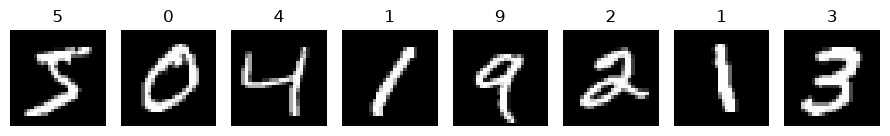

In [3]:
plt.figure(figsize=(9, 2))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i]); plt.axis("off")
plt.tight_layout(); plt.show()

## 2. Preprocess the data for the fully connected network

A Dense layer expects a flat vector, so I:
- flatten every 28x28 image into 784 pixels
- divide by 255, so the pixels are between 0 and 1
- one-hot encode the labels (3 → `[0,0,0,1,0,0,0,0,0,0]`)

The instructions use `keras.utils.np_utils.to_categorical()`. That module doesn't exist in current Keras anymore, and the same function is now `keras.utils.to_categorical()`.

In [4]:
x_train_fc = x_train.reshape(-1, 784).astype("float32") / 255.0   # (60000, 784)
x_test_fc = x_test.reshape(-1, 784).astype("float32") / 255.0     # (10000, 784)

y_train_oh = to_categorical(y_train, 10)
y_test_oh = to_categorical(y_test, 10)

print("x_train_fc:", x_train_fc.shape, "| x_test_fc:", x_test_fc.shape)
print("label", y_train[0], "->", y_train_oh[0])

x_train_fc: (60000, 784) | x_test_fc: (10000, 784)
label 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Build and train the fully connected network

My network: 784 inputs → Dense 256 (ReLU) → Dense 128 (ReLU) → Dense 10 (softmax). I compile it with Adam, categorical cross-entropy and accuracy. I train for 10 epochs with batch size 128, and keep 10% of the training images aside as a validation set to watch for overfitting.

In [5]:
fc_model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),     # one probability per digit
])
fc_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
fc_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
t0 = time.time()
fc_hist = fc_model.fit(x_train_fc, y_train_oh, epochs=10, batch_size=128,
                       validation_split=0.1, verbose=2)
fc_time = time.time() - t0

fc_loss, fc_acc = fc_model.evaluate(x_test_fc, y_test_oh, verbose=0)
print(f"Fully connected network - test accuracy: {fc_acc:.4f}, test loss: {fc_loss:.4f}, training time: {fc_time:.0f}s")

Epoch 1/10


422/422 - 2s - 5ms/step - accuracy: 0.9157 - loss: 0.2904 - val_accuracy: 0.9643 - val_loss: 0.1162


Epoch 2/10


422/422 - 1s - 3ms/step - accuracy: 0.9659 - loss: 0.1158 - val_accuracy: 0.9727 - val_loss: 0.0889


Epoch 3/10


422/422 - 1s - 3ms/step - accuracy: 0.9786 - loss: 0.0733 - val_accuracy: 0.9718 - val_loss: 0.0854


... (11 outputs left out)

422/422 - 2s - 4ms/step - accuracy: 0.9948 - loss: 0.0164 - val_accuracy: 0.9730 - val_loss: 0.1083


Epoch 10/10


422/422 - 2s - 4ms/step - accuracy: 0.9961 - loss: 0.0123 - val_accuracy: 0.9742 - val_loss: 0.1043


Fully connected network - test accuracy: 0.9730, test loss: 0.1021, training time: 16s


**What this shows:** the fully connected network reaches a **test accuracy of 0.9730**, so 270 of the 10,000 test digits are wrong. The training accuracy keeps climbing to 0.9961, but the validation loss is lowest at epoch 3 (0.0854) and then rises to 0.1043. After about 3 epochs the network starts memorizing the training digits instead of learning more general shapes.

## 4. Preprocess the data for the CNN

A Conv2D layer needs images with a channel dimension, so I reshape to (60000, 28, 28, 1). The `1` is the single grayscale channel. I normalize with 255 again and reuse the one-hot labels from step 2.

In [7]:
x_train_cnn = x_train.reshape(60000, 28, 28, 1).astype("float32") / 255.0
x_test_cnn = x_test.reshape(10000, 28, 28, 1).astype("float32") / 255.0

print("x_train_cnn:", x_train_cnn.shape, "| x_test_cnn:", x_test_cnn.shape)
print("y_train_oh:", y_train_oh.shape)

x_train_cnn: (60000, 28, 28, 1) | x_test_cnn: (10000, 28, 28, 1)
y_train_oh: (60000, 10)


## 5. Build and train the CNN

My CNN has two Conv2D + MaxPool2D blocks, then a Flatten layer and the Dense layers:
- Conv2D 32 filters 3x3 → MaxPool2D 2x2 (28x28 → 26x26 → 13x13)
- Conv2D 64 filters 3x3 → MaxPool2D 2x2 (13x13 → 11x11 → 5x5)
- Flatten → Dense 128 (ReLU) → Dense 10 (softmax)

It is compiled and trained exactly like the fully connected network (Adam, 10 epochs, batch 128, 10% validation), so the only difference is the architecture.

In [8]:
cnn_model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),   # 32 small filters look for edges and strokes
    layers.MaxPool2D((2, 2)),                        # keep the strongest response in each 2x2 area
    layers.Conv2D(64, (3, 3), activation="relu"),   # combines strokes into bigger shapes
    layers.MaxPool2D((2, 2)),
    layers.Flatten(),                                # 5x5x64 feature maps -> 1600 numbers
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
cnn_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
tf.keras.utils.set_random_seed(42)
t0 = time.time()
cnn_hist = cnn_model.fit(x_train_cnn, y_train_oh, epochs=10, batch_size=128,
                         validation_split=0.1, verbose=2)
cnn_time = time.time() - t0

cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test_oh, verbose=0)
print(f"CNN - test accuracy: {cnn_acc:.4f}, test loss: {cnn_loss:.4f}, training time: {cnn_time:.0f}s")

Epoch 1/10


422/422 - 8s - 20ms/step - accuracy: 0.9322 - loss: 0.2268 - val_accuracy: 0.9822 - val_loss: 0.0595


Epoch 2/10


422/422 - 6s - 14ms/step - accuracy: 0.9808 - loss: 0.0617 - val_accuracy: 0.9893 - val_loss: 0.0414


Epoch 3/10


422/422 - 7s - 15ms/step - accuracy: 0.9870 - loss: 0.0420 - val_accuracy: 0.9893 - val_loss: 0.0385


... (11 outputs left out)

422/422 - 12s - 28ms/step - accuracy: 0.9968 - loss: 0.0101 - val_accuracy: 0.9897 - val_loss: 0.0451


Epoch 10/10


422/422 - 6s - 15ms/step - accuracy: 0.9972 - loss: 0.0083 - val_accuracy: 0.9862 - val_loss: 0.0737


CNN - test accuracy: 0.9873, test loss: 0.0487, training time: 82s


**What this shows:** the CNN reaches a **test accuracy of 0.9873**, so only 127 test digits are wrong. Its validation loss is lowest at epoch 4 (0.0361) and goes up to 0.0737 by epoch 10, so it starts to overfit too. Dropout or EarlyStopping would help here, but I kept both models plain and trained them the same way to make the comparison fair.

## 6. Compare the performance

I put the two models side by side: test accuracy, number of wrong test images, parameters and training time.

In [10]:
fc_pred = fc_model.predict(x_test_fc, verbose=0).argmax(axis=1)
cnn_pred = cnn_model.predict(x_test_cnn, verbose=0).argmax(axis=1)

comparison = pd.DataFrame({
    "model": ["Fully connected", "CNN"],
    "test accuracy": [round(fc_acc, 4), round(cnn_acc, 4)],
    "wrong test images (of 10,000)": [int((fc_pred != y_test).sum()), int((cnn_pred != y_test).sum())],
    "parameters": [fc_model.count_params(), cnn_model.count_params()],
    "training time (s)": [round(fc_time), round(cnn_time)],
})
comparison

,model,test accuracy,"wrong test images (of 10,000)",parameters,training time (s)
0,Fully connected,0.9730,270,235146,16
1,CNN,0.9873,127,225034,82


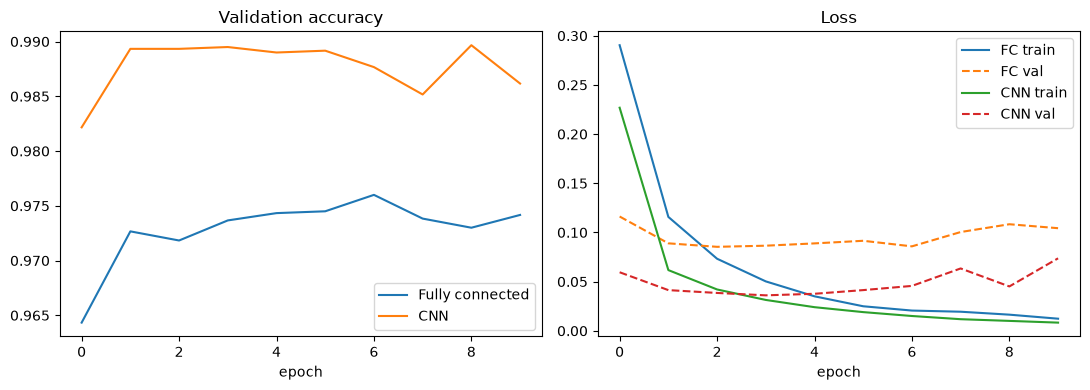

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fc_hist.history["val_accuracy"], label="Fully connected")
axes[0].plot(cnn_hist.history["val_accuracy"], label="CNN")
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(fc_hist.history["loss"], label="FC train"); axes[1].plot(fc_hist.history["val_loss"], "--", label="FC val")
axes[1].plot(cnn_hist.history["loss"], label="CNN train"); axes[1].plot(cnn_hist.history["val_loss"], "--", label="CNN val")
axes[1].set_title("Loss"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

Finally, some test digits that the fully connected network got wrong but the CNN got right:

196 digits fixed by the CNN | 53 digits the CNN broke


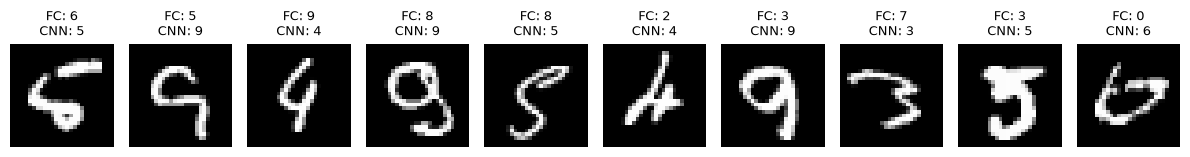

In [12]:
fixed = np.where((fc_pred != y_test) & (cnn_pred == y_test))[0]
print(len(fixed), "digits fixed by the CNN |",
      int(((fc_pred == y_test) & (cnn_pred != y_test)).sum()), "digits the CNN broke")
plt.figure(figsize=(12, 2.6))
for k, i in enumerate(fixed[:10]):
    plt.subplot(1, 10, k + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title(f"FC: {fc_pred[i]}\nCNN: {cnn_pred[i]}", fontsize=9); plt.axis("off")
plt.tight_layout(); plt.show()

**My analysis:**
- The CNN wins clearly: **0.9873 vs 0.9730** test accuracy. That is 1.4 points more, and the number of wrong digits drops from 270 to 127, more than half.
- The CNN gets this with slightly *fewer* parameters (225,034 vs 235,146). So the gain comes from the architecture, not from a bigger model.
- Why: the fully connected network gets 784 separate numbers and doesn't know which pixels are neighbors. If a digit is shifted by two pixels, it looks like a completely different input. The CNN's 3x3 filters slide over the whole image, so the same stroke detector works anywhere, and max pooling makes it tolerant to small shifts. The second conv layer combines strokes into loops and corners, which is what separates a 4 from a 9 or a 3 from an 8.
- The CNN fixed 196 digits that the fully connected network got wrong, and got 53 wrong that the fully connected network had right.
- The cost is speed: on my CPU the CNN needed 82 s for 10 epochs against 16 s, because every filter is applied at every position of the image.
- Both models start overfitting after 3 to 4 epochs (validation loss goes up while training loss keeps falling), so with more time I would add Dropout or EarlyStopping.

## Conclusion
With the same optimizer, epochs and batch size, the CNN made less than half the mistakes of the fully connected network (test accuracy 0.9873 vs 0.9730), with fewer parameters. For images, keeping the 2D structure with convolution and pooling matters more than adding Dense neurons.